# **Clustering**

**Clustering is unsupervised learning**. In clustering there is no answer column. You give the algorithm only the features, and it groups rows that look similar to each other. It finds the groups, but it does not tell you what they mean.

# **The core idea**

Clustering groups data points so that points within a group are similar and points across groups are different. It is unsupervised: there are no labels, only the data and a definition of “similarity” (usually distance).

**Two things always matter:**

- Distance measure (Euclidean, Manhattan, cosine...)

- Feature scaling: if one feature is in thousands and another in decimals, the big one dominates. Standardize first.

# Clustering Project

Clustering the passes of the 2 teams England & Spain in Womens World Cup Final 2023 due to the start and end of the pass into 5 Clusters

## Import Libraries 

In [30]:
import pandas as pd
from statsbombpy import sb
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from mplsoccer import Pitch

## Get the match events from statsbomb api

In [ ]:
df = sb.events(match_id=3906390)
df.head(5)

## Filter the features used in the model

In [6]:
df = df[['team', 'player', 'type', 'location', 'pass_end_location']]
df.head(5)

,team,player,type,location,pass_end_location
0,Spain Women's,NaN,Starting XI,NaN,NaN
1,England Women's,NaN,Starting XI,NaN,NaN
2,England Women's,NaN,Half Start,NaN,NaN
3,Spain Women's,NaN,Half Start,NaN,NaN
4,Spain Women's,NaN,Half Start,NaN,NaN


## Choose only the passes

In [8]:
passes_df = df[df['type'] == 'Pass']
passes_df.head(5)    

,team,player,type,location,pass_end_location
6,England Women's,Ella Toone,Pass,"[61.0, 40.1]","[51.1, 38.2]"
7,England Women's,Keira Walsh,Pass,"[51.1, 38.0]","[27.8, 47.3]"
8,England Women's,Millie Bright,Pass,"[27.8, 47.4]","[29.5, 62.7]"
9,England Women's,Jessica Carter,Pass,"[44.7, 74.4]","[89.1, 70.2]"
10,Spain Women's,Olga Carmona García,Pass,"[31.0, 9.9]","[40.3, 8.4]"


## Split the location feature and the pass end location to x and y (the point in the pitch)

In [11]:
passes_df[['start_x', 'start_y']] = pd.DataFrame(passes_df['location'].tolist(), index=passes_df.index)
passes_df[['end_x', 'end_y']]     = pd.DataFrame(passes_df['pass_end_location'].tolist(), index=passes_df.index)
passes_df.head(5)

,team,player,type,location,pass_end_location,start_x,start_y,end_x,end_y
6,England Women's,Ella Toone,Pass,"[61.0, 40.1]","[51.1, 38.2]",61.0,40.1,51.1,38.2
7,England Women's,Keira Walsh,Pass,"[51.1, 38.0]","[27.8, 47.3]",51.1,38.0,27.8,47.3
8,England Women's,Millie Bright,Pass,"[27.8, 47.4]","[29.5, 62.7]",27.8,47.4,29.5,62.7
9,England Women's,Jessica Carter,Pass,"[44.7, 74.4]","[89.1, 70.2]",44.7,74.4,89.1,70.2
10,Spain Women's,Olga Carmona García,Pass,"[31.0, 9.9]","[40.3, 8.4]",31.0,9.9,40.3,8.4


In [13]:
passes_df = passes_df.dropna(subset=['end_x', 'end_y'])

## Split the data set of the 2 teams to cluster the passes of each team separately

In [16]:
eng_df = passes_df[passes_df['team'] == 'England Women\'s']
spn_df = passes_df[passes_df['team'] == 'Spain Women\'s']


# **K-means (centroid-based)**

Idea: each cluster is a cloud around a center (centroid).

**Algorithm**

- Choose k and place k initial centroids.

- Assign every point to its nearest centroid.

- Update each centroid to the mean of its points.

- Repeat 2 and 3 until assignments stop changing.


Goal it minimizes: total squared distance from each point to its centroid (inertia / WCSS).

Worked example: points 1, 2, 4, 9, 10, 12 with k = 2, starting centers 1 and 2. It converges to clusters {1, 2, 4} and {9, 10, 12}, with centers 2.33 and 10.33.

Weakness: initialization. Bad starting centers can lead to a poor local optimum. Fixes:

- k-means++, which spreads the initial centers apart
- Multiple restarts, keeping the run with the lowest inertia

## Create the clusstering model for the English Team

In [ ]:
eng_X = eng_df[['start_x', 'start_y', 'end_x', 'end_y']]

eng_kmeans = KMeans(n_clusters=5)
eng_df['cluster'] = eng_kmeans.fit_predict(eng_X)
eng_df.head(5)

,team,player,type,location,pass_end_location,start_x,start_y,end_x,end_y,cluster
6,England Women's,Ella Toone,Pass,"[61.0, 40.1]","[51.1, 38.2]",61.0,40.1,51.1,38.2,4
7,England Women's,Keira Walsh,Pass,"[51.1, 38.0]","[27.8, 47.3]",51.1,38.0,27.8,47.3,1
8,England Women's,Millie Bright,Pass,"[27.8, 47.4]","[29.5, 62.7]",27.8,47.4,29.5,62.7,1
9,England Women's,Jessica Carter,Pass,"[44.7, 74.4]","[89.1, 70.2]",44.7,74.4,89.1,70.2,4
12,England Women's,Georgia Stanway,Pass,"[76.2, 71.0]","[77.1, 76.3]",76.2,71.0,77.1,76.3,4


In [26]:
eng_df.cluster.value_counts()

cluster
4    106
1    102
2     67
0     67
3     66
Name: count, dtype: int64

## Create the clusstering model for the Spain Team


In [27]:
spn_X = spn_df[['start_x', 'start_y', 'end_x', 'end_y']]
spn_kmeans = KMeans(n_clusters=5)
spn_df['cluster'] = spn_kmeans.fit_predict(spn_X)
spn_df.head(5)

,team,player,type,location,pass_end_location,start_x,start_y,end_x,end_y,cluster
10,Spain Women's,Olga Carmona García,Pass,"[31.0, 9.9]","[40.3, 8.4]",31.0,9.9,40.3,8.4,1
11,Spain Women's,Teresa Abelleira Dueñas,Pass,"[42.5, 7.2]","[43.9, 9.1]",42.5,7.2,43.9,9.1,1
13,Spain Women's,Olga Carmona García,Pass,"[68.8, 0.1]","[77.1, 2.8]",68.8,0.1,77.1,2.8,2
14,Spain Women's,Jennifer Hermoso Fuentes,Pass,"[74.6, 3.5]","[68.8, 3.2]",74.6,3.5,68.8,3.2,2
28,Spain Women's,Catalina Thomas Coll Lluch,Pass,"[7.9, 36.9]","[12.1, 55.4]",7.9,36.9,12.1,55.4,3


In [28]:
spn_df.cluster.value_counts()

cluster
1    147
0    121
2    113
3     91
4     47
Name: count, dtype: int64

## plotting the clusters of passes for the england team on the pitch


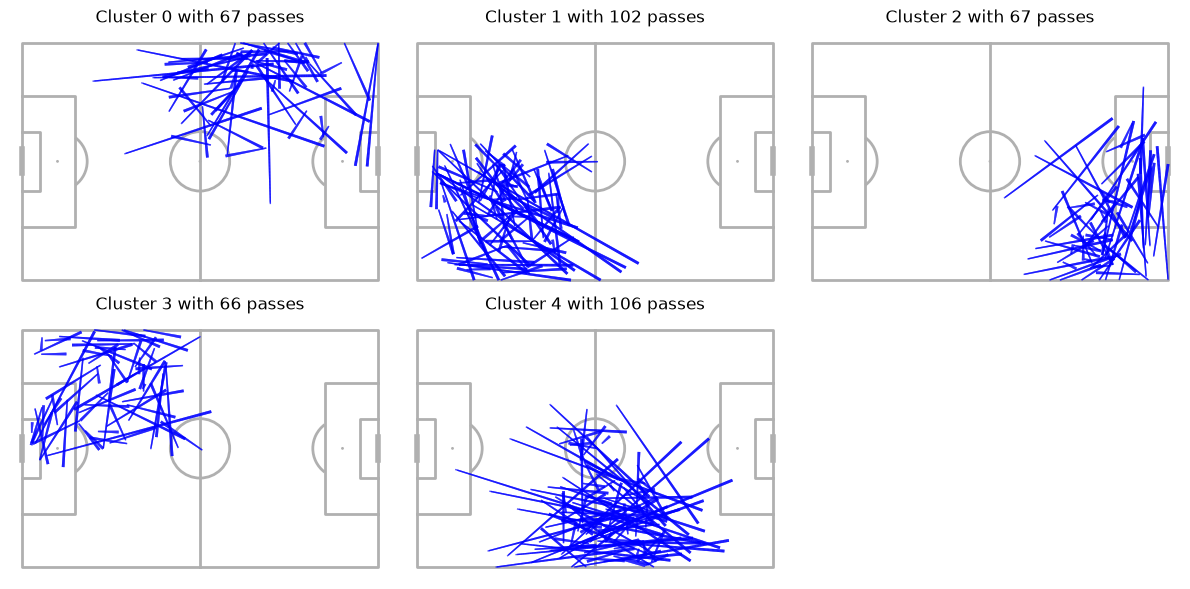

In [ ]:
def plot_player_fw_passes(player_stats: pd.DataFrame, alpha=0.7):
    cluster_ids = sorted(player_stats['cluster'].dropna().unique())

    fig, axes = plt.subplots(
        2, 3, figsize=(12, 6), squeeze=False
    )
    pitch = Pitch(pitch_type='statsbomb')

    for cluster_id, ax in zip(cluster_ids, axes.flat):
        pitch.draw(ax=ax)
        cluster_df = player_stats[player_stats['cluster'] == cluster_id]

        for x in cluster_df.to_dict(orient='records'):
            pitch.lines(
                x['start_x'], x['start_y'], x['end_x'], x['end_y'],
                lw=2, comet=True, ax=ax, color='b', alpha=alpha
            )

        ax.set_title(f'Cluster {cluster_id} with {len(cluster_df)} passes')


    for ax in axes.flat[len(cluster_ids):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()

plot_player_fw_passes(eng_df)


## plotting the clusters of passes for the spain team on the pitch

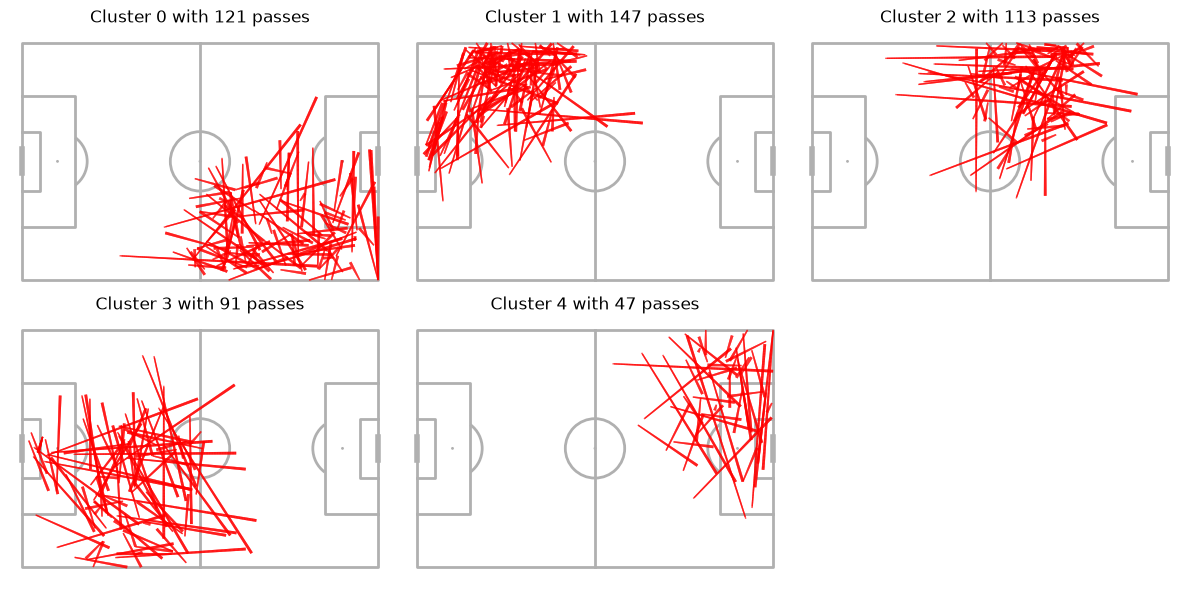

In [69]:
def plot_player_fw_passes(player_stats: pd.DataFrame, alpha=0.7):

    cluster_ids = sorted(player_stats['cluster'].dropna().unique())

    fig, axes = plt.subplots(
        2, 3, figsize=(12, 6), squeeze=False
    )
    pitch = Pitch(pitch_type='statsbomb')

    for cluster_id, ax in zip(cluster_ids, axes.flat):
        pitch.draw(ax=ax)
        cluster_df = player_stats[player_stats['cluster'] == cluster_id]

        for x in cluster_df.to_dict(orient='records'):
            pitch.lines(
                x['start_x'], x['start_y'], x['end_x'], x['end_y'],
                lw=2, comet=True, ax=ax, color='r', alpha=alpha
            )

        ax.set_title(f'Cluster {cluster_id} with {len(cluster_df)} passes')

    for ax in axes.flat[len(cluster_ids):]:
        ax.set_visible(False)

    ax2.set_title('Spain Women\'s Passes')

    plt.tight_layout()
    plt.show()

plot_player_fw_passes(spn_df)


## plotting the location of the most common passes for both teams on the same figure



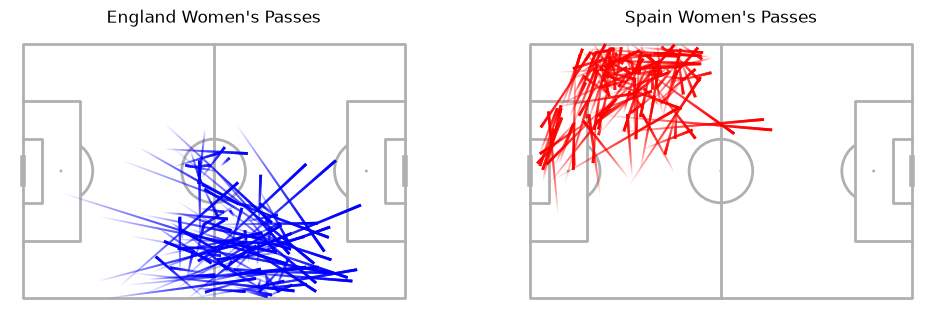

In [72]:
from matplotlib.gridspec import GridSpec
top_england_passes = eng_df[eng_df['cluster'].isin(eng_df['cluster'].value_counts().head(1).index)]
top_spain_passes = spn_df[spn_df['cluster'].isin(spn_df['cluster'].value_counts().head(1).index)]

pitch = Pitch(pitch_type='statsbomb')
colors = ['red']
fig = plt.figure(figsize=(12, 8))
gs = GridSpec(2, 2, figure=fig)

ax1 = fig.add_subplot(gs[0, 0])
pitch.draw(ax=ax1)
ax1.set_title('England Women\'s Passes')
pitch.lines(
        top_england_passes['start_x'],
        top_england_passes['start_y'],
        top_england_passes['end_x'],
        top_england_passes['end_y'],
        lw=2,
        transparent=True,
        comet=True,
        ax=ax1,
        color='b'
    )

ax2 = fig.add_subplot(gs[0, 1])
pitch.draw(ax=ax2)
ax2.set_title('Spain Women\'s Passes')
pitch.lines(
        top_spain_passes['start_x'],
        top_spain_passes['start_y'],
        top_spain_passes['end_x'],
        top_spain_passes['end_y'],
        lw=2,
        transparent=True,
        comet=True,
        ax=ax2,
        color='r'
    )
plt.show()

# **Observations** 
### **England Women’s (blue)**
- Most passes are in the upper right half of the pitch, centred on the middle of the field around the centre circle.

- They spread across both halves, with many passes crossing the halfway line.

- The lines are long and spread out in many directions, some quite flat across the pitch. This suggests passing from the middle of the field, rather than from one zone.

- The lower half of the pitch is almost empty, so England concentrated their play on one side.

### **Spain Women’s (red)**
- Almost all passes are in the lower-left corner, close to one goal and its penalty area.

- The cluster is dense and compact. There are very few passes on the right half of the pitch.

- Most lines are short, so these are short, close passes in a small area.
